In [2]:
# ============================================================
# 0. 엑셀 파일 직접 업로드
# ============================================================
from google.colab import files

uploaded = files.upload()  # 여기서 "파일 선택" 버튼 눌러서 엑셀 업로드하세요

# 업로드한 파일명 자동으로 가져오기
EXCEL_PATH = list(uploaded.keys())[0]
print("업로드된 파일:", EXCEL_PATH)

Saving 위험요소_채점_기록시트_결과입력완료.xlsx to 위험요소_채점_기록시트_결과입력완료.xlsx
업로드된 파일: 위험요소_채점_기록시트_결과입력완료.xlsx


In [3]:
# ============================================================
# 1. 기본 설정 (한글 폰트 + 파스텔 색상)
# ============================================================
import openpyxl
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np
import subprocess

subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-nanum"], capture_output=True)
fm.fontManager.addfont("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")
plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False

COLOR_CLOVA = "#A8D8EA"
COLOR_GEMINI = "#FFB6B9"
COLOR_ACCENT = "#B5EAD7"
COLOR_TEXT = "#4A4A4A"

In [4]:
# ============================================================
# 2. 엑셀에서 데이터 읽어오기
# ============================================================
wb = openpyxl.load_workbook(EXCEL_PATH, data_only=True)
ws_ai = wb["AI 채점용"]
ws_sev = wb["심각도 신뢰성"]
ws_sum = wb["채점기준"]

def get_type_accuracy(ws, start, end):
    from collections import Counter
    by_type = {"균열": Counter(), "포트홀": Counter()}
    for r in range(start, end + 1):
        true_t = ws.cell(row=r, column=3).value
        ox = ws.cell(row=r, column=6).value
        if true_t in by_type and ox in ("O", "X"):
            by_type[true_t][ox] += 1
    result = {}
    for t, cnt in by_type.items():
        total = cnt["O"] + cnt["X"]
        result[t] = round(cnt["O"] / total * 100, 2) if total > 0 else None
    return result

clova_type_acc = get_type_accuracy(ws_ai, 3, 302)
gemini_type_acc = get_type_accuracy(ws_ai, 303, 602)
clova_overall = ws_sum["B48"].value
gemini_overall = ws_sum["C48"].value

clova_spearman = ws_sum["B49"].value
gemini_spearman = ws_sum["C49"].value
clova_kendall = ws_sum["B50"].value
gemini_kendall = ws_sum["C50"].value
clova_interp = ws_sum["B51"].value
gemini_interp = ws_sum["C51"].value

severity_map = {"경미": 1, "보통": 2, "심각": 3, "긴급": 4}

def get_scatter_data(ws, start, end):
    sev, area = [], []
    for r in range(start, end + 1):
        s = ws.cell(row=r, column=3).value
        a = ws.cell(row=r, column=5).value
        if s in severity_map and isinstance(a, (int, float)):
            sev.append(severity_map[s])
            area.append(a)
    return sev, area

gemini_sev, gemini_area = get_scatter_data(ws_sev, 3, 302)
clova_sev, clova_area = get_scatter_data(ws_sev, 303, 602)

print("데이터 로드 완료")

데이터 로드 완료


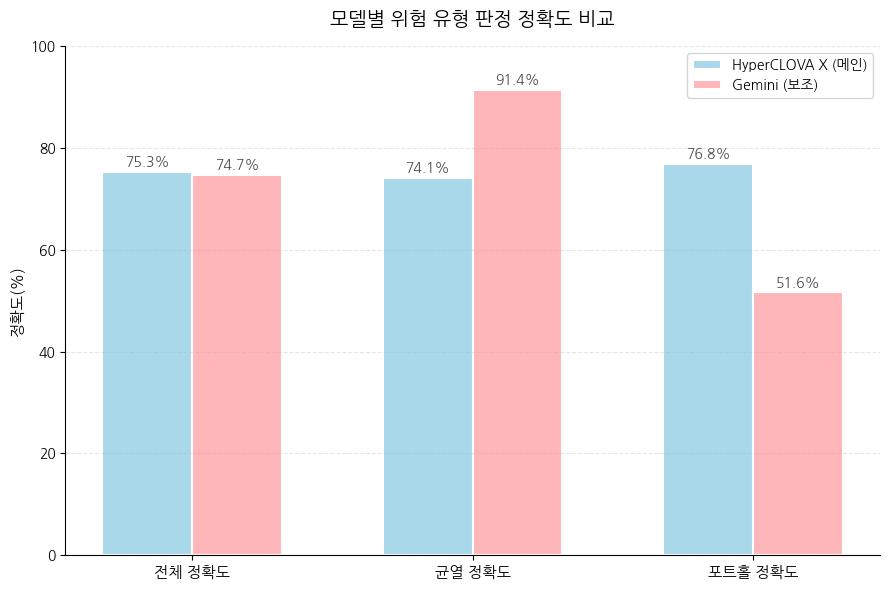

In [5]:
# ============================================================
# 3. 그래프 1 - 모델 비교 막대그래프
# ============================================================
categories = ["전체 정확도", "균열 정확도", "포트홀 정확도"]
clova_vals = [clova_overall, clova_type_acc["균열"], clova_type_acc["포트홀"]]
gemini_vals = [gemini_overall, gemini_type_acc["균열"], gemini_type_acc["포트홀"]]

x = np.arange(len(categories))
width = 0.32

fig1, ax1 = plt.subplots(figsize=(9, 6))
bars1 = ax1.bar(x - width/2, clova_vals, width, label="HyperCLOVA X (메인)", color=COLOR_CLOVA, edgecolor="white", linewidth=1.5)
bars2 = ax1.bar(x + width/2, gemini_vals, width, label="Gemini (보조)", color=COLOR_GEMINI, edgecolor="white", linewidth=1.5)

for bars in [bars1, bars2]:
    for bar in bars:
        h = bar.get_height()
        ax1.annotate(f"{h:.1f}%", xy=(bar.get_x() + bar.get_width()/2, h),
                     xytext=(0, 4), textcoords="offset points", ha="center",
                     fontsize=10, color=COLOR_TEXT, fontweight="bold")

ax1.set_ylabel("정확도(%)", fontsize=11)
ax1.set_title("모델별 위험 유형 판정 정확도 비교", fontsize=14, fontweight="bold", pad=15)
ax1.set_xticks(x)
ax1.set_xticklabels(categories, fontsize=11)
ax1.set_ylim(0, 100)
ax1.legend(fontsize=10, loc="upper right")
ax1.spines[["top", "right"]].set_visible(False)
ax1.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

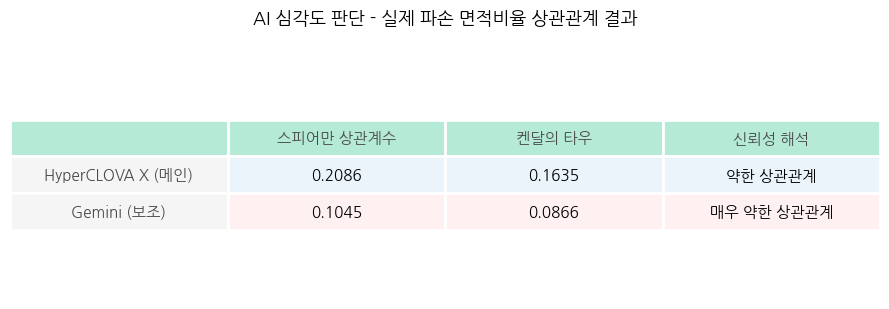

In [6]:
# ============================================================
# 4. 그래프 2 - 상관계수 결과표
# ============================================================
fig2, ax2 = plt.subplots(figsize=(9, 3.2))
ax2.axis("off")

table_data = [
    ["", "스피어만 상관계수", "켄달의 타우", "신뢰성 해석"],
    ["HyperCLOVA X (메인)", f"{clova_spearman:.4f}", f"{clova_kendall:.4f}", clova_interp],
    ["Gemini (보조)", f"{gemini_spearman:.4f}", f"{gemini_kendall:.4f}", gemini_interp],
]

table = ax2.table(cellText=table_data, loc="center", cellLoc="center")
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 2.2)

for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor("white")
    cell.set_linewidth(2)
    if row == 0:
        cell.set_facecolor(COLOR_ACCENT)
        cell.set_text_props(fontweight="bold", color=COLOR_TEXT)
    elif col == 0:
        cell.set_facecolor("#F5F5F5")
        cell.set_text_props(fontweight="bold", color=COLOR_TEXT)
    elif row == 1:
        cell.set_facecolor("#EAF4FA")
    else:
        cell.set_facecolor("#FFF0F1")

plt.title("AI 심각도 판단 - 실제 파손 면적비율 상관관계 결과", fontsize=13, fontweight="bold", pad=20)
plt.tight_layout()
plt.show()

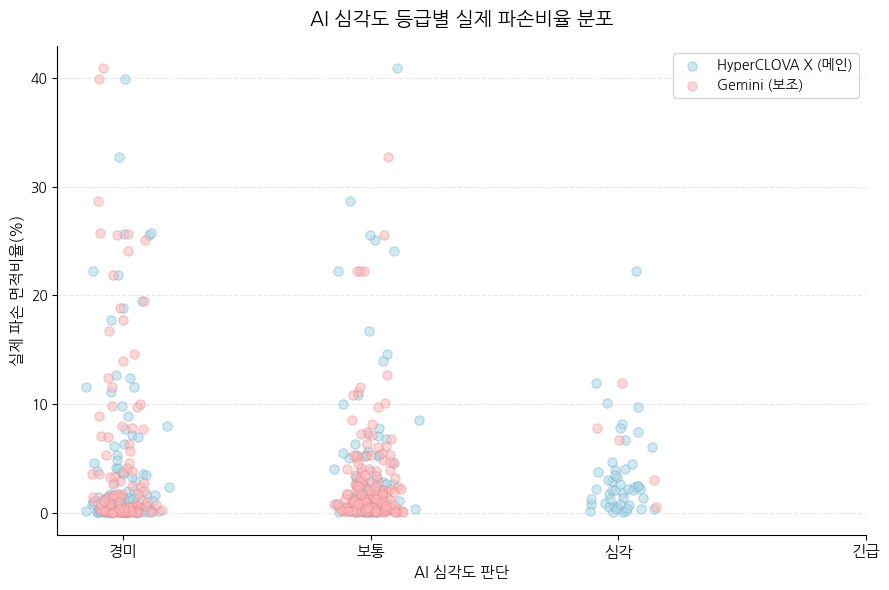

In [7]:
# ============================================================
# 5. 그래프 3 - 산점도
# ============================================================
fig3, ax3 = plt.subplots(figsize=(9, 6))

jitter_c = np.random.normal(0, 0.06, len(clova_sev))
jitter_g = np.random.normal(0, 0.06, len(gemini_sev))

ax3.scatter(np.array(clova_sev) + jitter_c, clova_area, alpha=0.55, s=45,
            color=COLOR_CLOVA, edgecolor="#6FA8C7", linewidth=0.6, label="HyperCLOVA X (메인)")
ax3.scatter(np.array(gemini_sev) + jitter_g, gemini_area, alpha=0.55, s=45,
            color=COLOR_GEMINI, edgecolor="#E08A8D", linewidth=0.6, label="Gemini (보조)")

ax3.set_xticks([1, 2, 3, 4])
ax3.set_xticklabels(["경미", "보통", "심각", "긴급"], fontsize=11)
ax3.set_xlabel("AI 심각도 판단", fontsize=11)
ax3.set_ylabel("실제 파손 면적비율(%)", fontsize=11)
ax3.set_title("AI 심각도 등급별 실제 파손비율 분포", fontsize=14, fontweight="bold", pad=15)
ax3.legend(fontsize=10)
ax3.spines[["top", "right"]].set_visible(False)
ax3.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
# ============================================================
# 6. 전체 그래프 한 번에 저장
# ============================================================
fig1.savefig("그래프1_모델비교_막대그래프.png", dpi=150, bbox_inches="tight")
fig2.savefig("그래프2_상관계수_결과표.png", dpi=150, bbox_inches="tight")
fig3.savefig("그래프3_산점도.png", dpi=150, bbox_inches="tight")
print("✅ 그래프 3개 저장 완료 — 왼쪽 파일 목록에서 다운로드하세요")

✅ 그래프 3개 저장 완료 — 왼쪽 파일 목록에서 다운로드하세요
